# TP3_big — Satisfaction des passagers aériens : un pipeline Big Data avec Spark

**Batist Aureille — identifiant ID18** · TP3, cas *big data* (dossier `TP3_ID18/Big/`)

### Ma contribution

**1. Le notebook est-il correct ?** Oui, il s'exécute de bout en bout sans erreur (23 cellules de code). Je le lance depuis le dossier `Big/`, avec Python 3.12, PySpark 3.5 et Java 11. Le premier lancement dure environ 15 minutes : il génère les données (≈ 1,5 Go, non versionnées) et entraîne les modèles.

**2. Problèmes rencontrés**

*Dans le notebook Kaggle d'origine* (détail en section 9.1) :

| # | Problème | Conséquence |
|---|---|---|
| 1 | Chemins Kaggle en dur (`/kaggle/input/...`) | Ne tourne pas en dehors de Kaggle |
| 2 | `dropna()` appliqué au jeu de test | Le modèle refuse 83 passagers : impossible en production |
| 3 | La note 0 est traitée comme la plus mauvaise note | Elle signifie « non applicable » |
| 4 | Les durées de retard sont supprimées | Perte d'information |
| 5 | Arbre de décision sans limite de profondeur | Apprentissage par cœur (100 % en apprentissage) |
| 6 | Comparaison des modèles sur la seule accuracy | Masque le compromis précision / rappel |
| 7 | Imports inutilisés, modèles entraînés deux fois | Code trompeur et plus lent |

*Pendant le passage au Big Data* :

| # | Problème | Solution retenue |
|---|---|---|
| 8 | Avec 100 copies (13 millions de lignes), l'entraînement saturait la mémoire Java de mon Mac (16 Go) | 50 copies (6,5 millions de lignes), 10 Go pour le *driver*, données relues depuis le disque (zone gold) |
| 9 | Les copies sont des quasi-doublons : un découpage au hasard surestime le score de près de 4 points | Découpage apprentissage / test par passager d'origine (section 6.4) |
| 10 | Les k plus proches voisins du notebook d'origine n'existent pas dans Spark MLlib | Modèles utilisés : régression logistique, arbre, forêt aléatoire, gradient boosting |

**3. Modifications apportées**

Le notebook d'origine n'utilise pas PySpark (pandas et scikit-learn sur 130 000 lignes). Je l'ai entièrement refait avec PySpark :

- Data : génération distribuée de 6,5 millions de lignes (50 copies légèrement modifiées, avec des défauts réalistes), lecture avec un schéma explicite, data lake en Parquet (brut → bronze → silver → gold).
- EDA : agrégations distribuées ; comparaison pandas / Spark CSV / Spark Parquet à trois volumes.
- Prétraitement : doublons, valeurs aberrantes, formats incohérents ; stockage partitionné par mois.
- Transformation : `Pipeline` Spark ML (`Imputer`, `SQLTransformer`, `StringIndexer`, `VectorAssembler`, `StandardScaler`).
- ML : quatre modèles Spark MLlib.
- Éval : AUC, précision, rappel, F1 ; comparaison avec le notebook d'origine ; piège des quasi-doublons ; courbe d'apprentissage.
- Déploiement : sauvegarde du `PipelineModel` complet dans `artefacts/`.
- J'ai aussi ajouté l'effet du nombre de cœurs (section 8) et corrigé les problèmes 1 à 7.

**4. Autres informations utiles**

- Le dossier `bigdata/` (≈ 1,5 Go) n'est pas dans le dépôt : le notebook le recrée à partir de `airline_dataset/`.
- Il faut Java 11 dans `~/hadoop_tp` (installé par le notebook du TP1). Les dépendances sont dans `requirements.txt`.
- Étiquetage du processus IA : Chaque section est précédée d'une cellule `## [Étape]` qui donne l'étape du processus IA. J'ai ajouté trois étiquettes : Environnement, Benchmark et Conclusion.

**Présentation**

**Point de départ** : le notebook Kaggle [*Airline Satisfaction — EDA & ML 96 %*](https://www.kaggle.com/code/nadenkhaled/airline-satisfaction-eda-ml-96). Il prédit si un passager est **satisfait** ou **neutre/insatisfait** à partir de son profil, de son vol et des notes qu'il donne à 14 services. Le meilleur modèle est XGBoost, à 96,3 % d'accuracy. Tout est fait en pandas et scikit-learn, sur 130 000 passagers (15 Mo).

**Objectif du TP** : refaire ce projet comme un **projet Big Data**. On imagine que la compagnie collecte ces questionnaires sur trois ans, dans tous ses vols : **6,5 millions de réponses** (900 Mo de CSV) au lieu de 130 000. À ce volume, la démarche change :

| Étape | Notebook d'origine (pandas) | Ce TP (Spark) |
|---|---|---|
| **Data** | `pd.read_csv` d'un fichier | Génération de l'univers Big Data, ingestion CSV → **Parquet partitionné** (data lake) |
| **EDA** | graphiques sur toutes les lignes | **agrégations distribuées** dans Spark ; seuls les petits résultats vont dans pandas |
| **Pré-traitement** | `dropna`, `map` | contrôle qualité à grande échelle : doublons, valeurs aberrantes, formats |
| **Transformation** | `StandardScaler` scikit-learn | **Pipeline Spark ML** : `Imputer`, `StringIndexer`, `VectorAssembler`, `StandardScaler` |
| **ML** | 5 modèles scikit-learn | **Spark MLlib** : régression logistique, arbre, forêt aléatoire, gradient boosting |
| **Évaluation** | accuracy | AUC, précision, rappel, F1, courbe d'apprentissage, **piège des quasi-doublons** |
| **Déploiement** | — | sauvegarde du `PipelineModel` (l'API Docker sera faite dans un second temps) |

## [Environnement]

Section 0 — Démarrage de Spark, dossiers de travail et fonctions utilitaires.

## 0. Mise en place de Spark

Même configuration que les TP1 et TP2 : Spark 3.5 en mode `local[*]` (les 10 cœurs du Mac jouent le rôle des machines d'un cluster) et Java 11 installé dans `~/hadoop_tp`. On donne **10 Go** de mémoire au *driver* : en mode local, c'est la mémoire de tous les *executors*.

In [1]:
import os, sys, glob, time, shutil, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

os.environ["JAVA_HOME"] = sorted(glob.glob(str(Path.home() / "hadoop_tp" / "jdk-11*")))[-1] + "/Contents/Home"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, DataFrame, Window, functions as F, types as T

def creer_spark(master="local[*]"):
    spark = (SparkSession.builder.master(master).appName("Airline Big Data")
             .config("spark.driver.memory", "10g")
             .config("spark.ui.showConsoleProgress", "false")
             .getOrCreate())
    spark.sparkContext.setLogLevel("ERROR")
    return spark

spark = creer_spark()
sc = spark.sparkContext
print(f"Spark {spark.version} | master = {sc.master} | parallélisme = {sc.defaultParallelism} | UI : {sc.uiWebUrl}")

SOURCE = Path("airline_dataset")                  # les 2 CSV Kaggle d'origine
BIG = Path("bigdata"); BIG.mkdir(exist_ok=True)   # le « data lake » local (ignoré par git)
ART = Path("artefacts"); ART.mkdir(exist_ok=True)
SEED = 42

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8172b3", "#52514e"]
BLEU, ORANGE, VERT, JAUNE, VIOLET, GRIS = PALETTE
plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titleweight": "bold", "font.size": 10,
})

def chrono(f):
    t0 = time.perf_counter(); r = f(); return r, time.perf_counter() - t0

def taille(p):
    p = Path(p); return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e6

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/12 16:48:51 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 3.5.9 | master = local[*] | parallélisme = 10 | UI : http://eduroam-2-248-123.univ-amu.fr:4040


## [Data]

Section 1 — Données d'origine, génération de l'univers Big Data (6,5 millions de lignes), ingestion et choix du format de stockage.

---
# 1. Data — construire et ingérer l'univers Big Data

## 1.1 Les données d'origine

Deux fichiers Kaggle (`teejmahal20/airline-passenger-satisfaction`) : `train.csv` (103 904 passagers) et `test.csv` (25 976). Chaque ligne est un questionnaire :
- **profil** : genre, fidélité (*Customer Type*), âge, motif du voyage, classe ;
- **vol** : distance, retards au départ et à l'arrivée ;
- **14 notes de service** de 0 à 5 (wifi, confort du siège, embarquement en ligne…) ;
- **cible** : `satisfied` ou `neutral or dissatisfied`.

⚠️ Le notebook d'origine lit ces fichiers depuis `/kaggle/input/...` (chemins Kaggle en dur). Ici, ils sont dans `airline_dataset/`.

In [2]:
for f in ["train.csv", "test.csv"]:
    assert (SOURCE / f).exists(), f"Fichier manquant : {SOURCE / f}"
source = (spark.read.option("header", True).option("inferSchema", True).csv(str(SOURCE / "train.csv")).withColumn("split", F.lit("train"))
          .unionByName(spark.read.option("header", True).option("inferSchema", True).csv(str(SOURCE / "test.csv")).withColumn("split", F.lit("test")))
          .drop("_c0"))                       # _c0 = ancien index pandas (« Unnamed: 0 »)
print(f"{source.count():,} questionnaires | {len(source.columns)} colonnes | {taille(SOURCE):.0f} Mo de CSV")
source.groupBy("split").count().show()

129,880 questionnaires | 25 colonnes | 15 Mo de CSV


+-----+------+
|split| count|
+-----+------+
|train|103904|
| test| 25976|
+-----+------+



## 1.2 Générer l'univers Big Data : 50 copies légèrement modifiées

On ne dispose pas de 6,5 millions de vrais questionnaires : on les **simule** à partir des 130 000 réels. Copier 50 fois le fichier, comme au TP1, donnerait 50 lignes **identiques** par passager, ce qui n'est pas réaliste. Chaque copie est donc **légèrement modifiée**, en respectant la logique des données :

| Colonne | Modification (copies 1 à 49 ; la copie 0 = les données d'origine, intactes) |
|---|---|
| `id` | nouvel identifiant unique : `id + copie × 1 000 000` ; on garde `id_origine` et `copie` (traçabilité) |
| `Age` | ± 2 ans environ (bruit gaussien), borné à [7, 85] |
| `Flight Distance` | ± 5 % environ, au moins 31 miles |
| 14 notes de service | 8 % des notes bougent d'un point (bornées à [1, 5]) ; une note **0 = « non applicable »** reste 0 |
| Retard au départ | ± 15 % environ (bruit multiplicatif) ; 5 % des vols à l'heure prennent 1 à 5 min de retard |
| Retard à l'arrivée | nouveau retard au départ + écart d'origine (arrivée − départ) ± 2 min : les deux restent cohérents ; une valeur manquante reste manquante |
| `flight_date` (nouvelle) | date de vol tirée au hasard entre 2023 et 2025, sans lien avec la satisfaction. Elle sert à **organiser le stockage** (partitions) |
| `satisfaction`, profil | inchangés : le lien entre profil, notes et satisfaction est préservé |

Pour que l'étape de pré-traitement ait du sens, on injecte aussi des **défauts réalistes** (suggérés par IA), comme dans une vraie collecte :
- **doublons** : 0,05 % des lignes sont chargées deux fois (double envoi d'un fichier) ;
- **formats incohérents** : 0,1 % des genres sont écrits en majuscules (`MALE`) ;
- **valeurs aberrantes** : 0,02 % des âges valent `999` (code « inconnu » d'un système source).

La génération est elle-même un **traitement distribué** : Spark fait un produit cartésien des 130 000 lignes avec les 50 numéros de copie (`crossJoin`), applique les modifications en parallèle et écrit 40 fichiers CSV.

In [3]:
NOTES = ["Inflight wifi service", "Departure/Arrival time convenient", "Ease of Online booking", "Gate location",
         "Food and drink", "Online boarding", "Seat comfort", "Inflight entertainment", "On-board service",
         "Leg room service", "Baggage handling", "Checkin service", "Inflight service", "Cleanliness"]

def generer_univers(n_copies, sortie, seed=SEED):
    "Écrit n_copies versions bruitées des 129 880 questionnaires dans le dossier `sortie` (CSV)."
    bruit = lambda k: F.randn(seed + k)
    hasard = lambda k: F.rand(seed + k)
    df = source.crossJoin(F.broadcast(spark.range(n_copies).withColumnRenamed("id", "copie")))
    orig = F.col("copie") == 0
    df = (df.withColumn("id_origine", F.col("id"))
            .withColumn("id", F.col("id") + F.col("copie") * 1_000_000)
            .withColumn("Age", F.when(orig, F.col("Age")).otherwise(
                F.least(F.lit(85), F.greatest(F.lit(7), F.round(F.col("Age") + 2 * bruit(1)).cast("int")))))
            .withColumn("Flight Distance", F.when(orig, F.col("Flight Distance")).otherwise(
                F.greatest(F.lit(31), F.round(F.col("Flight Distance") * (1 + 0.05 * bruit(2))).cast("int")))))
    for i, c in enumerate(NOTES):
        u = hasard(100 + i)
        decalage = F.when(u < 0.04, -1).when(u < 0.08, 1).otherwise(0)
        df = df.withColumn(c, F.when(orig | (F.col(c) == 0), F.col(c))
                              .otherwise(F.least(F.lit(5), F.greatest(F.lit(1), F.col(c) + decalage))))
    dep, arr = F.col("Departure Delay in Minutes"), F.col("Arrival Delay in Minutes")
    nouveau_dep = (F.when(dep == 0, F.when(hasard(3) < 0.05, F.floor(hasard(4) * 5) + 1).otherwise(0))
                    .otherwise(F.round(dep * F.exp(0.15 * bruit(5))))).cast("int")
    df = (df.withColumn("_dep", F.when(orig, dep).otherwise(nouveau_dep))
            .withColumn("Arrival Delay in Minutes", F.when(orig | arr.isNull(), arr)
                        .otherwise(F.greatest(F.lit(0.0), F.col("_dep") + (arr - dep) + F.round(2 * bruit(6)))))
            .withColumn("Departure Delay in Minutes", F.col("_dep")).drop("_dep")
            .withColumn("flight_date", F.date_add(F.lit("2023-01-01"), F.floor(hasard(7) * 1095).cast("int"))))
    # --- défauts de collecte
    df = (df.withColumn("Gender", F.when(hasard(8) < 0.001, F.upper("Gender")).otherwise(F.col("Gender")))
            .withColumn("Age", F.when(hasard(9) < 0.0002, F.lit(999)).otherwise(F.col("Age"))))
    df = df.unionByName(df.sample(fraction=0.0005, seed=seed + 10))           # lignes chargées deux fois
    shutil.rmtree(sortie, ignore_errors=True)
    df.repartition(40).write.option("header", True).csv(str(sortie))

N_COPIES = 50          # 100 copies (13 M de lignes) saturaient la mémoire du Mac (16 Go) pendant l'entraînement
UNIVERS = {1: SOURCE, 10: BIG / "brut_x10", N_COPIES: BIG / f"brut_x{N_COPIES}"}
for n in [10, N_COPIES]:
    if UNIVERS[n].exists():
        print(f"x{n} : déjà généré ({taille(UNIVERS[n]):,.0f} Mo)")
    else:
        _, t = chrono(lambda: generer_univers(n, UNIVERS[n]))
        print(f"x{n} : généré en {t:.0f} s → {taille(UNIVERS[n]):,.0f} Mo de CSV, {len(list(UNIVERS[n].glob('*.csv')))} fichiers")

x10 : déjà généré (179 Mo)
x50 : déjà généré (909 Mo)


## 1.3 Ingestion : lire le CSV brut avec un schéma explicite

Avec `inferSchema=True`, Spark lit **tout le fichier une première fois** pour deviner les types, puis une seconde fois pour le traitement. Sur 900 Mo, c'est coûteux. En production, on déclare le **schéma** : une seule lecture, et des types garantis.

In [4]:
SCHEMA = T.StructType(
    [T.StructField("id", T.LongType()), T.StructField("Gender", T.StringType()), T.StructField("Customer Type", T.StringType()),
     T.StructField("Age", T.IntegerType()), T.StructField("Type of Travel", T.StringType()), T.StructField("Class", T.StringType()),
     T.StructField("Flight Distance", T.IntegerType())]
    + [T.StructField(c, T.IntegerType()) for c in NOTES]
    + [T.StructField("Departure Delay in Minutes", T.IntegerType()), T.StructField("Arrival Delay in Minutes", T.DoubleType()),
       T.StructField("satisfaction", T.StringType()), T.StructField("split", T.StringType()),
       T.StructField("copie", T.LongType()), T.StructField("id_origine", T.LongType()), T.StructField("flight_date", T.DateType())])

_, t_infer = chrono(lambda: spark.read.option("header", True).option("inferSchema", True).csv(str(UNIVERS[N_COPIES])).schema)
brut = spark.read.option("header", True).schema(SCHEMA).csv(str(UNIVERS[N_COPIES]))
n_brut, t_count = chrono(brut.count)
print(f"Déduction du schéma (inferSchema) : {t_infer:.1f} s de lecture… avant même de commencer le travail")
print(f"Lecture avec schéma explicite + comptage : {t_count:.1f} s → {n_brut:,} lignes")

Déduction du schéma (inferSchema) : 3.5 s de lecture… avant même de commencer le travail
Lecture avec schéma explicite + comptage : 0.4 s → 6,497,172 lignes


**Lecture** : `inferSchema` impose une lecture complète du fichier juste pour deviner les types. Sur des téraoctets, cela prendrait des minutes, voire des heures. Avec un schéma déclaré, le comptage est presque instantané : Spark compte les lignes sans même découper les colonnes.

## 1.4 Stockage : CSV ou Parquet ?

Le CSV est un format **texte, ligne par ligne** : pour lire une seule colonne, il faut lire et découper toutes les lignes. **Parquet** est un format **binaire, en colonnes** et compressé, avec des statistiques par bloc (min, max). Spark ne lit alors que les colonnes utiles et peut sauter des blocs entiers.

On convertit le CSV brut en Parquet (zone « bronze » du data lake), puis on compare une même requête sur les deux formats.

In [5]:
BRONZE = BIG / "bronze_parquet"
if not BRONZE.exists():
    _, t = chrono(lambda: brut.write.parquet(str(BRONZE)))
    print(f"Conversion CSV → Parquet : {t:.0f} s")
bronze = spark.read.parquet(str(BRONZE))

requete = lambda df: (df.groupBy("Class").agg(F.avg((F.col("satisfaction") == "satisfied").cast("int")).alias("taux"),
                                               F.avg("Departure Delay in Minutes").alias("retard")).collect())
_, t_csv = chrono(lambda: requete(brut))
_, t_pq = chrono(lambda: requete(bronze))
pd.DataFrame({"taille (Mo)": [taille(UNIVERS[N_COPIES]), taille(BRONZE)], "requête (s)": [t_csv, t_pq]},
             index=["CSV", "Parquet"]).round(1)

,taille (Mo),requête (s)
CSV,908.7,1.6
Parquet,139.4,0.6


**Lecture** : Parquet est **environ 6 fois plus petit** que le CSV (compression par colonne : une colonne de notes de 1 à 5 se compresse très bien) et la requête est bien plus rapide. Spark ne lit que les 3 colonnes utiles parmi 28. C'est la raison pour laquelle les data lakes stockent en Parquet (ou ORC, Delta…), et pas en CSV.

## [EDA]

Section 2 — Analyse exploratoire distribuée : qualité des données, cible, profils, notes de service, retards, comparaison pandas / Spark.

---
# 2. EDA distribuée

**Règle** (déjà appliquée au TP2) : tous les calculs sur les 6,5 millions de lignes sont faits **dans Spark**. On ne rapatrie dans pandas (`toPandas()`) que des résultats **agrégés** de quelques dizaines de lignes, pour les tracer. Le notebook d'origine trace des histogrammes et des *violin plots* sur toutes les lignes, ce qui est impossible à ce volume : `toPandas()` sur 13 millions de lignes saturerait la mémoire du *driver*.

## 2.1 Vue d'ensemble et qualité des données

In [6]:
bronze.cache()
n = bronze.count()
print(f"{n:,} lignes | {bronze.select('id_origine').distinct().count():,} passagers d'origine | "
      f"vols du {bronze.agg(F.min('flight_date')).first()[0]} au {bronze.agg(F.max('flight_date')).first()[0]}")

qualite = bronze.select(
    *[F.sum(F.col(c).isNull().cast("int")).alias(c) for c in ["Arrival Delay in Minutes", "Age", "Gender"]],
    F.sum((~F.col("Age").between(7, 85)).cast("int")).alias("âge hors [7, 85]"),
    F.sum((~F.col("Gender").isin("Male", "Female")).cast("int")).alias("genre mal écrit"),
    (F.count("*") - F.countDistinct("id")).alias("id en double"),
).toPandas().T.rename(columns={0: "lignes concernées"})
qualite["%"] = (100 * qualite["lignes concernées"] / n).round(3)
qualite

6,497,172 lignes | 129,880 passagers d'origine | vols du 2023-01-01 au 2025-12-30


,lignes concernées,%
Arrival Delay in Minutes,19658,0.303
Age,0,0.000
Gender,0,0.000
"âge hors [7, 85]",1268,0.020
genre mal écrit,6452,0.099
id en double,3172,0.049


**Lecture** : l'EDA retrouve **exactement** les défauts injectés : 0,3 % de retards à l'arrivée manquants (comme dans les données d'origine), 0,02 % d'âges aberrants, 0,1 % de genres mal écrits et 0,05 % de doublons. Sur 6,5 millions de lignes, ces 0,05 % représentent tout de même plus de 3 000 questionnaires comptés deux fois : à grande échelle, même un taux de défauts très faible concerne beaucoup de lignes.

## 2.2 La cible : satisfaction

In [7]:
cible = (bronze.groupBy("split", "satisfaction").count()
         .withColumn("%", F.round(100 * F.col("count") / F.sum("count").over(Window.partitionBy("split")), 1))
         .orderBy("split", "satisfaction"))
cible.show()

+-----+--------------------+-------+----+
|split|        satisfaction|  count|   %|
+-----+--------------------+-------+----+
| test|neutral or dissat...| 728991|56.1|
| test|           satisfied| 570439|43.9|
|train|neutral or dissat...|2945411|56.7|
|train|           satisfied|2252331|43.3|
+-----+--------------------+-------+----+



**Lecture** : 43 % de satisfaits contre 57 % de neutres ou insatisfaits, aussi bien en apprentissage qu'en test. Les classes sont **un peu déséquilibrées**, sans excès. L'accuracy reste lisible, mais on regardera aussi l'**AUC** et le **F1**.

## 2.3 Profil des passagers et satisfaction

Pour chaque variable catégorielle, on calcule dans Spark le **taux de satisfaction**. C'est plus lisible que les histogrammes empilés du notebook d'origine.

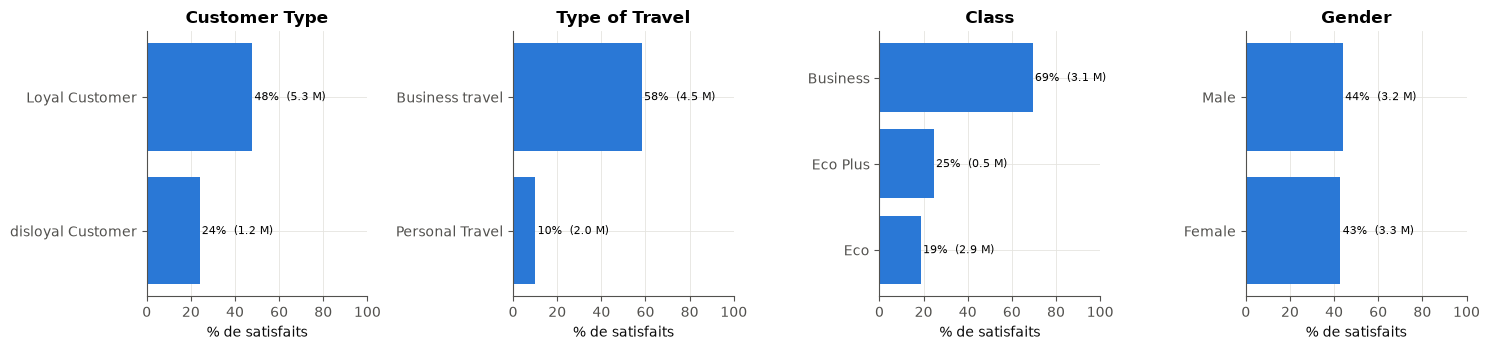

In [8]:
CATS = ["Customer Type", "Type of Travel", "Class", "Gender"]
satisf = (F.col("satisfaction") == "satisfied").cast("int")
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, c in zip(axes, CATS):
    agg = (bronze.filter(F.col("Gender").isin("Male", "Female")).groupBy(c)
           .agg(F.avg(satisf).alias("taux"), F.count("*").alias("n")).orderBy("taux").toPandas())
    ax.barh(agg[c], 100 * agg.taux, color=BLEU)
    for i, (t, k) in enumerate(zip(agg.taux, agg.n)):
        ax.text(100 * t + 1, i, f"{t:.0%}  ({k / 1e6:.1f} M)", va="center", fontsize=8)
    ax.set(title=c, xlim=(0, 100), xlabel="% de satisfaits")
plt.tight_layout(); plt.show()

**Lecture**
- Le **motif du voyage** et la **classe** séparent très fortement les passagers : environ 7 sur 10 sont satisfaits en *Business*, contre moins de 2 sur 10 en *Eco*. En voyage personnel, à peine 1 sur 10 est satisfait.
- Les clients **fidèles** sont nettement plus souvent satisfaits que les autres.
- Le **genre** n'a quasiment aucun effet.

## 2.4 Les notes de service

On « dépivote » les 14 colonnes de notes en une seule colonne (`stack`), puis on calcule en un seul passage le taux de satisfaction pour chaque couple *(service, note)*.

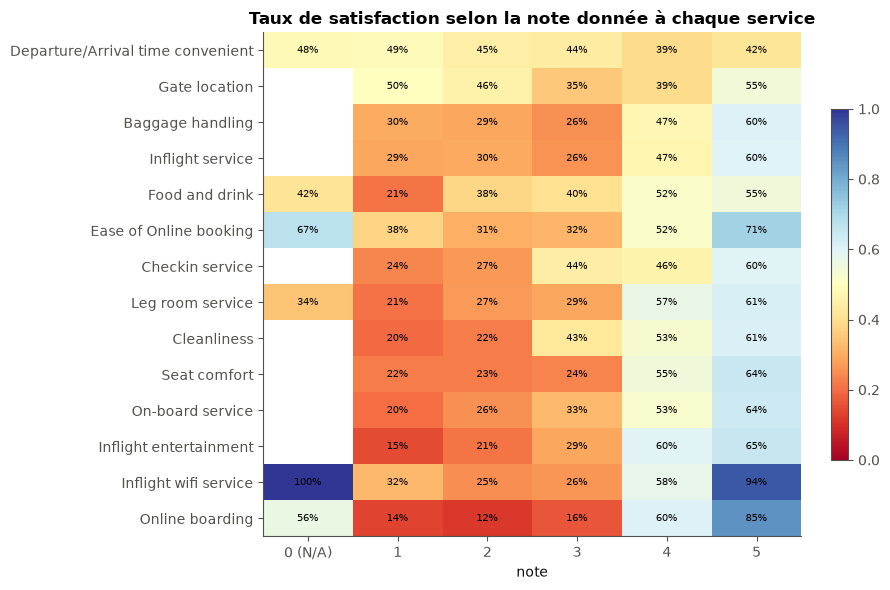

Notes à 0 (« non applicable ») : {'Departure/Arrival time convenient': 334231, 'Ease of Online booking': 284252, 'Inflight wifi service': 195913, 'Online boarding': 154089, 'Leg room service': 29915}


In [9]:
stack_expr = "stack({}, {}) as (service, note)".format(len(NOTES), ", ".join(f"'{c}', `{c}`" for c in NOTES))
notes_long = bronze.select(satisf.alias("satisfait"), F.expr(stack_expr))
grille = (notes_long.groupBy("service", "note").agg(F.avg("satisfait").alias("taux"), F.count("*").alias("n"))
          .toPandas())
taux = grille.pivot(index="service", columns="note", values="taux")
effectif = grille.pivot(index="service", columns="note", values="n").fillna(0)
ordre = (taux[5] - taux[1]).sort_values().index
taux = taux.loc[ordre].where(effectif.loc[ordre] >= 1000)       # cases < 1 000 réponses masquées (non significatives)

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(taux.values, cmap="RdYlBu", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(taux.columns))); ax.set_xticklabels([f"{c}" + (" (N/A)" if c == 0 else "") for c in taux.columns])
ax.set_yticks(range(len(taux))); ax.set_yticklabels(taux.index); ax.grid(False)
for i in range(taux.shape[0]):
    for j in range(taux.shape[1]):
        if not np.isnan(taux.values[i, j]):
            ax.text(j, i, f"{taux.values[i, j]:.0%}", ha="center", va="center", fontsize=7)
ax.set(title="Taux de satisfaction selon la note donnée à chaque service", xlabel="note")
plt.colorbar(im, ax=ax, fraction=0.03); plt.tight_layout(); plt.show()
print("Notes à 0 (« non applicable ») :", effectif[0].astype(int).loc[lambda s: s > 0].sort_values(ascending=False).head(5).to_dict())

**Lecture**
- L'**embarquement en ligne**, le **wifi** et le **divertissement à bord** sont les services les plus liés à la satisfaction. Pour l'embarquement en ligne, on passe de 12-16 % de satisfaits avec une note de 1 à 3 à 85 % avec un 5 ; pour le wifi, jusqu'à 94 % avec un 5.
- À l'inverse, l'**emplacement de la porte** et la **commodité de l'horaire** n'ont presque pas d'effet.
- ⚠️ **La note 0 n'est pas une mauvaise note** : elle signifie « non applicable » (le passager n'a pas utilisé le service). Pour le wifi, les passagers qui ont mis 0 sont **tous satisfaits** (100 %), plus encore que ceux qui ont mis 5. Pour la plupart des autres services, la note 0 est trop rare pour être interprétée (cases blanches). Le notebook d'origine la traite comme une note numérique (la plus basse) et la normalise avec les autres. Les modèles à base d'arbres s'en accommodent, une régression logistique beaucoup moins. On ajoutera un indicateur « nombre de services non notés » en section 4.

## 2.5 Les retards

Quantiles (approxQuantile, erreur relative 0,1 %) :


  Departure Delay in Minutes   {'médiane': 0.0, '75 %': 12.0, '95 %': 78.0, '99 %': 182.0}


  Arrival Delay in Minutes     {'médiane': 2.0, '75 %': 13.0, '95 %': 79.0, '99 %': 182.0}


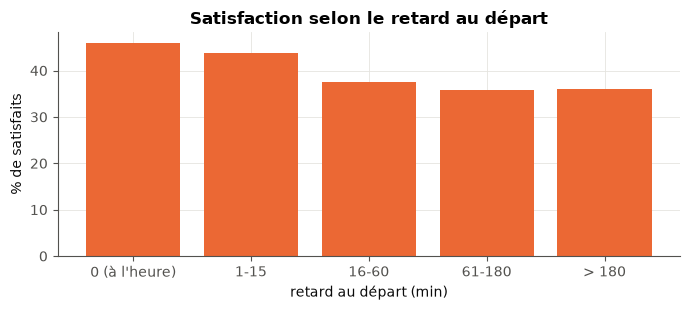

Corrélation retard départ / arrivée : 0.960


In [10]:
retards = ["Departure Delay in Minutes", "Arrival Delay in Minutes"]
print("Quantiles (approxQuantile, erreur relative 0,1 %) :")
for c in retards:
    print(f"  {c:28s}", dict(zip(["médiane", "75 %", "95 %", "99 %"], bronze.approxQuantile(c, [0.5, 0.75, 0.95, 0.99], 0.001))))

tranches = (F.when(F.col("Departure Delay in Minutes") == 0, "0 (à l'heure)")
             .when(F.col("Departure Delay in Minutes") <= 15, "1-15").when(F.col("Departure Delay in Minutes") <= 60, "16-60")
             .when(F.col("Departure Delay in Minutes") <= 180, "61-180").otherwise("> 180"))
par_retard = bronze.groupBy(tranches.alias("retard (min)")).agg(F.avg(satisf).alias("taux"), F.count("*").alias("n")).toPandas()
par_retard = par_retard.set_index("retard (min)").loc[["0 (à l'heure)", "1-15", "16-60", "61-180", "> 180"]]
corr = bronze.stat.corr(*retards)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(par_retard.index, 100 * par_retard.taux, color=ORANGE)
ax.set(title="Satisfaction selon le retard au départ", ylabel="% de satisfaits", xlabel="retard au départ (min)")
plt.tight_layout(); plt.show()
print(f"Corrélation retard départ / arrivée : {corr:.3f}")

**Lecture** : la moitié des vols partent à l'heure et quelques-uns ont des retards de plusieurs heures (distribution très **asymétrique**). La satisfaction baisse avec le retard, mais **modérément** : de 46 % à l'heure à environ 36 % au-delà d'une heure. Le retard compte moins que la classe ou le wifi. Retards au départ et à l'arrivée sont **corrélés à 0,96** : garder les deux n'apporte presque rien, d'où l'idée du notebook de les combiner.

## 2.6 Pourquoi Spark ? pandas contre Spark sur le même calcul

On mesure le temps d'une même étape d'EDA (taux de satisfaction et retard moyen par classe et motif de voyage, **lecture du fichier comprise**) pour les trois tailles d'univers, avec :
- **pandas** sur le CSV (en ne lisant que les 4 colonnes utiles, pour l'aider) ;
- **Spark** sur le CSV ;
- **Spark** sur Parquet.

,lignes,pandas (CSV),Spark (CSV),Spark (Parquet)
univers,,,,
x1,"129,880",0.12 s,0.12 s,0.17 s
x10,"1,299,432",1.36 s,0.40 s,0.24 s
x50,"6,497,172",5.54 s,1.43 s,0.45 s


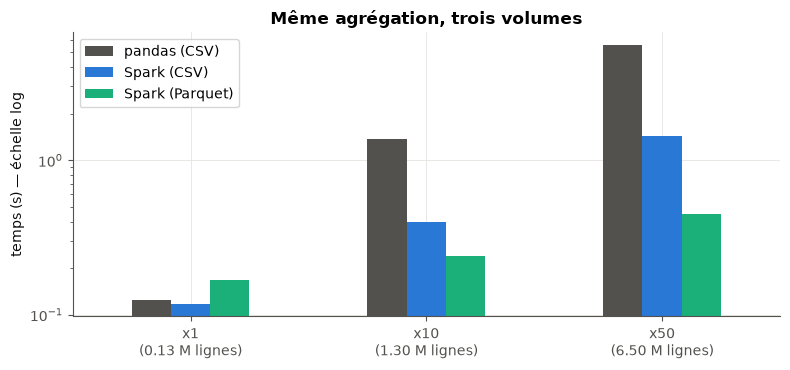

In [11]:
COLS = ["Class", "Type of Travel", "Departure Delay in Minutes", "satisfaction"]
def eda_pandas(chemin):
    fichiers = [chemin] if str(chemin).endswith(".csv") else sorted(Path(chemin).glob("*.csv"))
    d = pd.concat([pd.read_csv(f, usecols=COLS) for f in fichiers], ignore_index=True)
    d["satisfait"] = d.satisfaction == "satisfied"
    return d.groupby(["Class", "Type of Travel"]).agg(taux=("satisfait", "mean"), retard=("Departure Delay in Minutes", "mean"))

def eda_spark(df):
    return (df.groupBy("Class", "Type of Travel")
              .agg(F.avg(satisf).alias("taux"), F.avg("Departure Delay in Minutes").alias("retard")).toPandas())

# Parquet pour x1 et x10 (x50 existe déjà : zone bronze)
PARQUETS = {N_COPIES: BRONZE}
for k in [1, 10]:
    PARQUETS[k] = BIG / f"bench_parquet_x{k}"
    if not PARQUETS[k].exists():
        lecteur = spark.read.option("header", True)
        d = (lecteur.option("inferSchema", True).csv(str(SOURCE / "*.csv")) if k == 1 else lecteur.schema(SCHEMA).csv(str(UNIVERS[k])))
        d.write.parquet(str(PARQUETS[k]))

BENCH = []
for k in [1, 10, N_COPIES]:
    csv_spark = (spark.read.option("header", True).option("inferSchema", True).csv(str(SOURCE / "*.csv")) if k == 1
                 else spark.read.option("header", True).schema(SCHEMA).csv(str(UNIVERS[k])))
    chemin_pd = [SOURCE / "train.csv", SOURCE / "test.csv"] if k == 1 else UNIVERS[k]
    eda_spark(csv_spark)                                                   # échauffement
    t_pd = chrono(lambda: [eda_pandas(c) for c in (chemin_pd if k == 1 else [chemin_pd])])[1]
    t_sc = chrono(lambda: eda_spark(csv_spark))[1]
    t_sp = chrono(lambda: eda_spark(spark.read.parquet(str(PARQUETS[k]))))[1]
    BENCH.append({"univers": f"x{k}", "lignes": csv_spark.count(), "pandas (CSV)": t_pd, "Spark (CSV)": t_sc, "Spark (Parquet)": t_sp})
bench = pd.DataFrame(BENCH).set_index("univers")
display(bench.style.format({"lignes": "{:,}", "pandas (CSV)": "{:.2f} s", "Spark (CSV)": "{:.2f} s", "Spark (Parquet)": "{:.2f} s"}))

ax = bench.drop(columns="lignes").plot.bar(rot=0, logy=True, color=[GRIS, BLEU, VERT], figsize=(8, 3.8))
ax.set(title="Même agrégation, trois volumes", ylabel="temps (s) — échelle log", xlabel="")
ax.set_xticklabels([f"{u}\n({l / 1e6:.2f} M lignes)" for u, l in zip(bench.index, bench.lignes)])
plt.tight_layout(); plt.show()

**Lecture**
- Sur les **130 000 lignes d'origine**, les trois approches sont à égalité (≈ 0,1 s) : Spark n'a aucun intérêt à cette taille, comme le montrait déjà le TP1.
- Quand le volume augmente, **pandas croît linéairement**, car il lit et calcule sur un seul cœur. Spark répartit la lecture des 40 fichiers sur les 10 cœurs : environ 4 fois plus rapide en CSV à x50, et plus de 10 fois en Parquet, qui ne lit que les 4 colonnes utiles.
- pandas doit aussi tenir **toutes** les lignes en mémoire. Avec quelques centaines de millions de lignes, il ne pourrait plus fonctionner sur ce Mac, alors que Spark traite les fichiers par morceaux.

## [Prétraitement]

Section 3 — Nettoyage à grande échelle : noms de colonnes, formats, valeurs aberrantes, doublons ; écriture de la zone « silver ».

---
# 3. Pré-traitement à grande échelle

Le notebook d'origine se contente de `dropna()` et de dictionnaires `map`. Ici, on traite les défauts trouvés en 2.1 de façon **distribuée**, et on écrit le résultat dans la zone « silver » du data lake.

| Problème | Traitement |
|---|---|
| Noms de colonnes avec espaces et `/` | renommage en `snake_case` (plus sûr pour SQL, Parquet et les pipelines) |
| Genre mal écrit (`MALE`) | normalisation : `initcap` |
| Âge aberrant (`999`) | ligne supprimée : moins de 0,02 %, et on ne peut pas deviner le vrai âge |
| Lignes chargées deux fois | `dropDuplicates(["id"])` |
| Retard à l'arrivée manquant (0,3 %) | **pas** de suppression, contrairement au notebook ⚠️ : imputé **dans le pipeline ML** (section 4), avec la médiane calculée sur l'apprentissage uniquement |

⚠️ Le notebook d'origine supprime aussi les lignes incomplètes du **test** (`df_test.dropna`). En production, un modèle ne peut pas refuser de répondre parce qu'une valeur manque : il faut un traitement qui s'applique à **toute** nouvelle donnée.

In [12]:
def snake(c): return c.lower().replace("/", "_").replace(" ", "_").replace("-", "_")

def pretraiter(df):
    df = df.toDF(*[snake(c) for c in df.columns])
    return (df.withColumn("gender", F.initcap("gender"))
              .filter(F.col("age").between(7, 85))
              .dropDuplicates(["id"])
              .withColumn("annee", F.year("flight_date")).withColumn("mois", F.month("flight_date")))

SILVER = BIG / "silver_parquet"
silver_df = pretraiter(bronze)
if not SILVER.exists():
    _, t = chrono(lambda: silver_df.write.partitionBy("annee", "mois").parquet(str(SILVER)))
    print(f"Écriture de la zone silver (partitionnée par année et mois) : {t:.0f} s")
silver = spark.read.parquet(str(SILVER))
n_silver = silver.count()
print(f"Bronze : {n:,} lignes → silver : {n_silver:,} lignes ({n - n_silver:,} supprimées : doublons et âges aberrants)")
print("Genres :", [r[0] for r in silver.select("gender").distinct().collect()])
print(f"Partitions sur disque : {len(list(SILVER.glob('annee=*/mois=*')))} dossiers (3 ans × 12 mois)")
_ = bronze.unpersist()

Bronze : 6,497,172 lignes → silver : 6,492,732 lignes (4,440 supprimées : doublons et âges aberrants)


Genres : ['Female', 'Male']
Partitions sur disque : 36 dossiers (3 ans × 12 mois)


**Le partitionnement en action** : les données sont rangées dans des dossiers `annee=2024/mois=7/…`. Une requête qui filtre sur ces colonnes ne lit **que les dossiers utiles** (*partition pruning*) : on le voit dans le plan d'exécution (`PartitionFilters`).

In [13]:
un_mois = silver.filter((F.col("annee") == 2024) & (F.col("mois") == 7))
plan = un_mois._jdf.queryExecution().executedPlan().toString()
print([l.strip()[:160] for l in plan.splitlines() if "PartitionFilters" in l][0])
_, t_tout = chrono(lambda: silver.agg(F.avg("flight_distance")).collect())
_, t_mois = chrono(lambda: un_mois.agg(F.avg("flight_distance")).collect())
print(f"Moyenne sur tout : {t_tout:.2f} s | sur juillet 2024 seulement : {t_mois:.2f} s (1 dossier sur 36)")

+- FileScan parquet [id#13659L,gender#13660,customer_type#13661,age#13662,type_of_travel#13663,class#13664,flight_distance#13665,inflight_wifi_service#13666,dep


Moyenne sur tout : 0.26 s | sur juillet 2024 seulement : 0.05 s (1 dossier sur 36)


**Lecture** : environ 8 fois plus rapide, car Spark n'ouvre qu'**un dossier sur 36**. Dans un vrai data lake, où les analyses portent souvent sur une période (« le mois dernier »), choisir les bonnes colonnes de partitionnement est l'un des réglages qui comptent le plus.

## [Transformation]

Section 4 — Construction des variables et pipeline Spark ML de préparation.

---
# 4. Transformation : le pipeline Spark ML

Dans Spark ML, les transformations sont des **étapes d'un `Pipeline`**. On les ajuste (`fit`) sur l'apprentissage, puis on les applique (`transform`) à n'importe quelles données : test, ou nouveaux questionnaires en production. C'est l'équivalent du `Pipeline` de scikit-learn, mais **distribué**, et c'est ce qui garantit l'absence de fuite d'information : la médiane d'imputation et les moyennes de normalisation viennent **uniquement** de l'apprentissage.

| Étape | Rôle | Équivalent dans le notebook |
|---|---|---|
| `Imputer` | remplace le retard à l'arrivée manquant par la médiane (apprise sur l'apprentissage) | `dropna()` |
| `SQLTransformer` | crée de nouvelles variables en SQL : retard total, indicateur de retard, log du retard, classe ordinale, nombre de services non notés | `Total_Delay`, `Is_Delayed`, `class_map` |
| `StringIndexer` | encode les catégories binaires en 0/1 | dictionnaires `binary_maps` |
| `VectorAssembler` | regroupe les variables en un **vecteur** (format attendu par MLlib) | `x_train` (DataFrame) |
| `StandardScaler` | centre-réduit (pour la régression logistique) | `StandardScaler` |

⚠️ Le notebook d'origine **supprime** les retards et ne garde que l'indicateur « en retard / à l'heure » : il perd l'information de **durée** du retard. On garde ici l'indicateur **et** le log du retard total.

In [14]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import Imputer, StringIndexer, VectorAssembler, StandardScaler, SQLTransformer

NOTES_S = [snake(c) for c in NOTES]
imputer = Imputer(inputCols=["arrival_delay_in_minutes"], outputCols=["arrival_delay_imp"], strategy="median")
variables = SQLTransformer(statement=f'''
    SELECT *,
           departure_delay_in_minutes + arrival_delay_imp                 AS retard_total,
           CAST(departure_delay_in_minutes + arrival_delay_imp > 0 AS DOUBLE) AS en_retard,
           LOG1P(departure_delay_in_minutes + arrival_delay_imp)           AS log_retard,
           CASE `class` WHEN 'Eco' THEN 0 WHEN 'Eco Plus' THEN 1 ELSE 2 END  AS classe,
           {" + ".join(f"CAST({c} = 0 AS INT)" for c in NOTES_S)}          AS nb_non_notes,
           CAST(satisfaction = 'satisfied' AS DOUBLE)                      AS label
    FROM __THIS__''')
indexeur = StringIndexer(inputCols=["gender", "customer_type", "type_of_travel"],
                         outputCols=["genre_i", "fidele_i", "motif_i"], stringOrderType="alphabetAsc")
VARIABLES = ["genre_i", "fidele_i", "motif_i", "classe", "age", "flight_distance",
             "en_retard", "log_retard", "nb_non_notes"] + NOTES_S
assembleur = VectorAssembler(inputCols=VARIABLES, outputCol="features_brutes")
normaliseur = StandardScaler(inputCol="features_brutes", outputCol="features", withMean=True)
preparation = Pipeline(stages=[imputer, variables, indexeur, assembleur, normaliseur])

train_df = silver.filter("split = 'train'")
test_df = silver.filter("split = 'test'")
prep_model, t = chrono(lambda: preparation.fit(train_df))
print(f"Pipeline de préparation ajusté sur l'apprentissage en {t:.0f} s | médiane imputée : "
      f"{prep_model.stages[0].surrogateDF.first()[0]} min | {len(VARIABLES)} variables")

# Zone « gold » : les données prêtes pour le ML, écrites en Parquet. On les relit depuis le disque plutôt
# que de garder des millions de vecteurs en mémoire, qui saturaient la JVM pendant l'entraînement.
GOLD = BIG / "gold_parquet"
def ecrire_gold():
    shutil.rmtree(GOLD, ignore_errors=True)
    for nom, d in [("train", train_df), ("test", test_df)]:
        prep_model.transform(d).select("features", "label", "copie").write.parquet(str(GOLD / nom))
_, t = chrono(ecrire_gold)
train, test = spark.read.parquet(str(GOLD / "train")), spark.read.parquet(str(GOLD / "test"))
n_train, n_test = train.count(), test.count()
print(f"Zone gold écrite en {t:.0f} s ({taille(GOLD):.0f} Mo) | apprentissage : {n_train:,} lignes | test : {n_test:,} lignes")
train.select("features", "label").show(2, truncate=90)

Pipeline de préparation ajusté sur l'apprentissage en 6 s | médiane imputée : 2.0 min | 23 variables


Zone gold écrite en 7 s (191 Mo) | apprentissage : 5,194,181 lignes | test : 1,298,551 lignes
+------------------------------------------------------------------------------------------+-----+
|                                                                                  features|label|
+------------------------------------------------------------------------------------------+-----+
|[1.0150242494755017,-0.47276030117483364,-0.6708634104151828,-1.0677668487803251,0.3028...|  1.0|
|[1.0150242494755017,-0.47276030117483364,-0.6708634104151828,1.0093932458928905,1.22221...|  1.0|
+------------------------------------------------------------------------------------------+-----+
only showing top 2 rows



⚠️ **Piège des quasi-doublons** : chaque passager d'origine existe ici en 50 versions très proches. Si l'on découpait apprentissage et test **au hasard** parmi les 6,5 millions de lignes (`randomSplit`), presque chaque passager du test aurait des « jumeaux » dans l'apprentissage. Le modèle serait évalué sur des données qu'il a quasiment déjà vues. On découpe donc **par passager d'origine** : toutes les copies d'un passager du `train.csv` sont en apprentissage, toutes celles du `test.csv` sont en test. On mesurera l'effet de cette erreur en section 6.4.

## [ML]

Section 5 — Entraînement de quatre modèles Spark MLlib sur 5 millions de lignes.

---
# 5. Machine Learning avec Spark MLlib

MLlib propose la plupart des modèles du notebook d'origine, mais **pas tous** :

| Notebook (scikit-learn) | Spark MLlib | Remarque |
|---|---|---|
| `LogisticRegression` | `LogisticRegression` | ✓ |
| `DecisionTreeClassifier` | `DecisionTreeClassifier` | ✓ (profondeur limitée à 30 dans Spark) |
| — (importé, jamais utilisé) | `RandomForestClassifier` | ✓ |
| `XGBClassifier` | `GBTClassifier` | gradient boosting natif de Spark |
| `KNeighborsClassifier` | ✗ | k plus proches voisins : il faudrait comparer chaque ligne du test aux 5 millions de l'apprentissage, ce qui est inadapté au Big Data |
| `GaussianNB` | ✗ (seulement multinomial / Bernoulli) | et le plus faible du notebook (86 %) |

## 5.1 Entraînement des 4 modèles sur 5 millions de lignes

In [15]:
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

MODELES = {
    "Régression logistique": LogisticRegression(maxIter=50, regParam=0.0),
    "Arbre de décision": DecisionTreeClassifier(maxDepth=12, seed=SEED),
    "Forêt aléatoire": RandomForestClassifier(numTrees=40, maxDepth=12, seed=SEED),
    "Gradient boosting (GBT)": GBTClassifier(maxIter=50, maxDepth=5, seed=SEED)       # profondeur 6 : dépassement mémoire avec 8 Go,
}
FITTED, TEMPS_FIT = {}, {}
for nom, m in MODELES.items():
    FITTED[nom], TEMPS_FIT[nom] = chrono(lambda: m.fit(train))
    print(f"{nom:26s} entraîné en {TEMPS_FIT[nom]:5.0f} s")

Régression logistique      entraîné en    11 s


Arbre de décision          entraîné en     7 s


Forêt aléatoire            entraîné en   169 s


Gradient boosting (GBT)    entraîné en   110 s


**Lecture** : la régression logistique et l'arbre de décision s'entraînent en une dizaine de secondes sur 5 millions de lignes. La **forêt aléatoire** (40 arbres) et le **gradient boosting** (50 arbres construits l'un après l'autre) prennent plusieurs minutes. À chaque niveau de chaque arbre, Spark parcourt toutes les données pour calculer les meilleures coupures.

⚠️ **Réglage mémoire** : avec 100 copies (13 millions de lignes) et un gradient boosting de profondeur 6, la mémoire Java du Mac (8 puis 10 Go) saturait (`OutOfMemoryError`). D'où trois choix : **50 copies**, une profondeur de 5, et des données d'apprentissage relues depuis la zone **gold** sur disque plutôt que gardées en cache. Sur un vrai cluster, on ajouterait simplement des machines.

## [Éval]

Section 6 — Métriques sur le jeu de test, comparaison avec le notebook d'origine, matrice de confusion, piège des quasi-doublons, courbe d'apprentissage.

---
# 6. Évaluation

## 6.1 Métriques sur le test (1,3 million de questionnaires jamais vus)

| Métrique | Question |
|---|---|
| **Accuracy** | quelle part des passagers est bien classée ? |
| **AUC** | si l'on prend un satisfait et un insatisfait au hasard, le modèle donne-t-il un score plus élevé au satisfait ? (1 = parfait, 0,5 = hasard) |
| **Précision** (satisfait) | parmi ceux que le modèle dit satisfaits, combien le sont vraiment ? |
| **Rappel** (satisfait) | parmi les vrais satisfaits, combien le modèle en trouve-t-il ? |
| **F1** | moyenne harmonique de la précision et du rappel |

In [16]:
auc_eval = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
def evaluer(pred):
    m = lambda name, **kw: MulticlassClassificationEvaluator(labelCol="label", metricName=name, **kw).evaluate(pred)
    return {"accuracy": m("accuracy"), "AUC": auc_eval.evaluate(pred),
            "précision": m("precisionByLabel", metricLabel=1.0), "rappel": m("recallByLabel", metricLabel=1.0),
            "F1": m("fMeasureByLabel", metricLabel=1.0)}

PREDS, EVAL = {}, []
for nom, fm in FITTED.items():
    # on ne garde en cache que les colonnes utiles à l'évaluation (pas les vecteurs de 23 variables)
    PREDS[nom] = fm.transform(test).select("label", "prediction", "rawPrediction", "probability", "copie").cache()
    EVAL.append({"modèle": nom, **evaluer(PREDS[nom]), "entraînement (s)": TEMPS_FIT[nom]})
res = pd.DataFrame(EVAL).set_index("modèle")
res.style.format({c: "{:.4f}" for c in ["accuracy", "AUC", "précision", "rappel", "F1"]} | {"entraînement (s)": "{:.0f}"}) \
   .highlight_max(subset=["accuracy", "AUC", "F1"], color="#d4f1e4")

,accuracy,AUC,précision,rappel,F1,entraînement (s)
modèle,,,,,,
Régression logistique,0.8849,0.9527,0.8698,0.8679,0.8688,11
Arbre de décision,0.9405,0.9277,0.9447,0.9182,0.9312,7
Forêt aléatoire,0.9409,0.9873,0.9419,0.9222,0.9319,169
Gradient boosting (GBT),0.9372,0.9846,0.9373,0.9184,0.9278,110


**Lecture**
- La **forêt aléatoire** a la meilleure AUC (0,987) et la meilleure accuracy (94,1 %), juste devant le gradient boosting.
- L'**arbre de décision** seul a une bonne accuracy (94 %), mais la plus **faible AUC** (0,928) : un arbre ne donne qu'un petit nombre de probabilités différentes (une par feuille), donc il classe mal les passagers entre eux. Une forêt fait la moyenne de 40 arbres, d'où des probabilités beaucoup plus fines.
- La **régression logistique** plafonne à 88,5 %. Le lien entre notes et satisfaction n'est pas linéaire : une note de 4 à l'embarquement en ligne ne vaut pas « 4/5 » d'une note de 5.
- Pour tous les modèles, la **précision** dépasse le **rappel** : quand le modèle annonce « satisfait », il a presque toujours raison, mais il manque environ 8 % des vrais satisfaits.

## 6.2 Comparaison avec le notebook d'origine

Pour comparer à armes égales, on refait les modèles du notebook (scikit-learn et XGBoost, données d'origine, 104 000 lignes) et on les évalue sur les **mêmes 25 976 questionnaires** que notre copie 0 du test (le `test.csv` d'origine, intact).

In [17]:
from sklearn.linear_model import LogisticRegression as SkLR
from sklearn.tree import DecisionTreeClassifier as SkDT
from sklearn.preprocessing import StandardScaler as SkScaler
from sklearn.metrics import accuracy_score, roc_auc_score
from xgboost import XGBClassifier

def preparer_comme_notebook(d):
    d = d.drop(columns=["Unnamed: 0", "id"]).dropna().copy()            # ⚠️ dropna aussi sur le test
    for c, mp in {"Gender": {"Male": 0, "Female": 1}, "Customer Type": {"disloyal Customer": 0, "Loyal Customer": 1},
                  "Type of Travel": {"Personal Travel": 0, "Business travel": 1}, "Class": {"Eco": 0, "Eco Plus": 1, "Business": 2},
                  "satisfaction": {"neutral or dissatisfied": 0, "satisfied": 1}}.items():
        d[c] = d[c].map(mp)
    d["Is_Delayed"] = ((d["Departure Delay in Minutes"] + d["Arrival Delay in Minutes"]) > 0).astype(int)
    return d.drop(columns=["Departure Delay in Minutes", "Arrival Delay in Minutes"])
tr_pd, te_pd = preparer_comme_notebook(pd.read_csv(SOURCE / "train.csv")), preparer_comme_notebook(pd.read_csv(SOURCE / "test.csv"))
X_tr, y_tr, X_te, y_te = tr_pd.drop(columns="satisfaction"), tr_pd.satisfaction, te_pd.drop(columns="satisfaction"), te_pd.satisfaction
a_normaliser = ["Age", "Flight Distance"] + NOTES
sc_ = SkScaler().fit(X_tr[a_normaliser]); X_tr[a_normaliser] = sc_.transform(X_tr[a_normaliser]); X_te[a_normaliser] = sc_.transform(X_te[a_normaliser])

ref = []
for nom, m in [("LR (notebook)", SkLR(max_iter=1000)), ("Arbre (notebook, sans limite)", SkDT(random_state=SEED)),
               ("XGBoost (notebook)", XGBClassifier(random_state=SEED))]:
    m.fit(X_tr, y_tr); p = m.predict_proba(X_te)[:, 1]
    ref.append({"modèle": nom, "données": "x1, pandas", "accuracy": accuracy_score(y_te, p > 0.5), "AUC": roc_auc_score(y_te, p),
                "accuracy en apprentissage": accuracy_score(y_tr, m.predict(X_tr))})
for nom in FITTED:
    p0 = PREDS[nom].filter("copie = 0")
    ref.append({"modèle": nom, "données": f"x{N_COPIES}, Spark", **{k: v for k, v in evaluer(p0).items() if k in ("accuracy", "AUC")},
                "accuracy en apprentissage": MulticlassClassificationEvaluator(labelCol="label", metricName="accuracy")
                    .evaluate(FITTED[nom].transform(train.filter("copie = 0")))})
print(f"Test d'origine : {len(te_pd):,} lignes pour pandas (après dropna) | {PREDS[nom].filter('copie = 0').count():,} pour Spark (rien n'est supprimé)")
pd.DataFrame(ref).set_index("modèle").round(4)

Test d'origine : 25,893 lignes pour pandas (après dropna) | 25,971 pour Spark (rien n'est supprimé)


,données,accuracy,AUC,accuracy en apprentissage
modèle,,,,
LR (notebook),"x1, pandas",0.8717,0.9262,0.8745
"Arbre (notebook, sans limite)","x1, pandas",0.9459,0.9452,1.0000
XGBoost (notebook),"x1, pandas",0.9633,0.9951,0.9750
Régression logistique,"x50, Spark",0.8887,0.9552,0.8902
Arbre de décision,"x50, Spark",0.9515,0.9347,0.9564
Forêt aléatoire,"x50, Spark",0.9457,0.9899,0.9498
Gradient boosting (GBT),"x50, Spark",0.9442,0.9883,0.9446


**Lecture**
- ⚠️ **L'arbre sans limite du notebook apprend par cœur** : 100 % de réussite en apprentissage, 94,6 % en test. Notre arbre limité à 12 niveaux fait **mieux** en test (95,2 %), avec un écart apprentissage/test de moins de 1 point.
- Notre régression logistique fait mieux que celle du notebook (88,9 % contre 87,2 %), grâce aux variables ajoutées : log du retard et nombre de services non notés.
- **XGBoost reste le meilleur** (96,3 %, AUC 0,995). Le volume ne remplace pas la qualité. Nos modèles Spark apprennent sur des copies **bruitées** (8 % des notes décalées d'un point), et MLlib découpe chaque variable en 32 intervalles au maximum (`maxBins`), là où XGBoost cherche des coupures plus fines. Plus de données n'apporte rien si elles ne contiennent pas d'information nouvelle (voir 6.5).
- Côté Spark, le test compte 25 971 questionnaires (seuls 5 âges aberrants injectés sont retirés), contre 25 893 pour le notebook, qui supprime 83 passagers incomplets.

## 6.3 Matrice de confusion et variables importantes

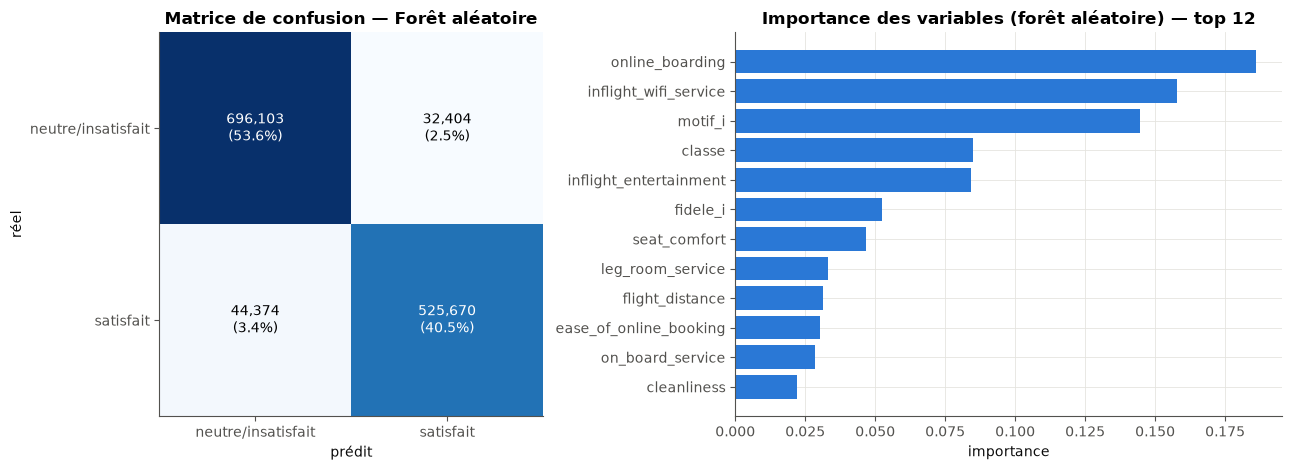

In [18]:
meilleur = res.AUC.idxmax()
cm = PREDS[meilleur].groupBy("label", "prediction").count().toPandas().pivot(index="label", columns="prediction", values="count")
imp = pd.Series(FITTED["Forêt aléatoire"].featureImportances.toArray(), index=VARIABLES).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.4]})
ax[0].imshow(cm.values, cmap="Blues"); ax[0].grid(False)
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, f"{cm.values[i, j]:,.0f}\n({cm.values[i, j] / cm.values.sum():.1%})", ha="center", va="center",
                   color="white" if cm.values[i, j] > cm.values.max() / 2 else "black")
ax[0].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["neutre/insatisfait", "satisfait"], yticklabels=["neutre/insatisfait", "satisfait"],
          xlabel="prédit", ylabel="réel", title=f"Matrice de confusion — {meilleur}")
ax[1].barh(imp.index[-12:], imp.values[-12:], color=BLEU)
ax[1].set(title="Importance des variables (forêt aléatoire) — top 12", xlabel="importance")
plt.tight_layout(); plt.show()

**Lecture**
- Les erreurs sont équilibrées : 2,5 % de faux « satisfaits » et 3,4 % de satisfaits non détectés.
- Les variables les plus importantes confirment l'EDA : l'**embarquement en ligne**, le **wifi**, le **motif du voyage**, la **classe** et le **divertissement à bord**. Pour la compagnie, ce sont les leviers prioritaires. Les retards, très commentés, ne figurent pas dans le top 12.

## 6.4 ⚠️ Le piège des quasi-doublons, mesuré

On compare deux façons de découper **le même** univers x10 (1,3 million de lignes), avec un arbre de décision profond (profondeur 25), le plus sensible au « par cœur » :
- **par passager** (notre méthode) : les copies d'un passager sont toutes du même côté ;
- **au hasard** (`randomSplit` 80/20) : les copies d'un passager sont réparties entre apprentissage et test.

Pour les deux, on compare le **score annoncé** (sur sa propre partie test) au **score réel**, mesuré sur des passagers **réellement nouveaux** : ceux du `test.csv`, dont aucune copie n'a servi à l'apprentissage.

In [19]:
x10 = pretraiter(spark.read.parquet(str(PARQUETS[10])).filter(F.col("copie").isNotNull()))
prep10 = preparation.fit(x10.filter("split = 'train'"))
x10_t = prep10.transform(x10).select("features", "label", "split").cache()
test_honnete = x10_t.filter("split = 'test'")
arbre = DecisionTreeClassifier(maxDepth=25, seed=SEED)
acc = MulticlassClassificationEvaluator(labelCol="label", metricName="accuracy")

apprentissage = x10.filter("split = 'train'")
# (a) par passager : on met de côté 20 % des PASSAGERS d'origine (avec toutes leurs copies) pour valider
passagers_val = apprentissage.select("id_origine").distinct().sample(fraction=0.2, seed=SEED)
val_p = prep10.transform(apprentissage.join(passagers_val, "id_origine", "left_semi")).select("features", "label")
app_p = prep10.transform(apprentissage.join(passagers_val, "id_origine", "left_anti")).select("features", "label")
# (b) au hasard : on mélange toutes les lignes, les copies d'un même passager tombent des deux côtés
app_h, val_h = prep10.transform(apprentissage).select("features", "label").randomSplit([0.8, 0.2], seed=SEED)

m_passager, m_hasard = arbre.fit(app_p), arbre.fit(app_h)
pd.DataFrame({
    "découpage par passager": {"score annoncé (validation)": acc.evaluate(m_passager.transform(val_p)),
                               "score réel (passagers du test.csv)": acc.evaluate(m_passager.transform(test_honnete))},
    "découpage au hasard": {"score annoncé (validation)": acc.evaluate(m_hasard.transform(val_h)),
                            "score réel (passagers du test.csv)": acc.evaluate(m_hasard.transform(test_honnete))},
}).round(4)

,découpage par passager,découpage au hasard
score annoncé (validation),0.9263,0.9649
score réel (passagers du test.csv),0.9273,0.9272


**Lecture** : avec un découpage **au hasard**, le score de validation (96,5 %) est **surestimé** de près de 4 points par rapport à ce que le modèle obtient sur de vrais nouveaux passagers. Il a été validé sur des « jumeaux » de passagers déjà vus pendant l'apprentissage. Avec le découpage **par passager**, le score annoncé (92,6 %) correspond au score réel (92,7 %). Dans un contexte Big Data, où les doublons et quasi-doublons sont fréquents (un même client, plusieurs vols ou questionnaires), il faut donc toujours **découper par entité** (client, passager…) et non par ligne.

## 6.5 Courbe d'apprentissage : faut-il vraiment 5 millions de lignes ?

Question clé du Big Data : **le volume améliore-t-il le modèle ?** On entraîne le meilleur modèle sur 0,1 %, 1 %, 10 % et 100 % de l'apprentissage, et on mesure le score et le temps.

In [20]:
COURBE = []
modele_courbe = MODELES[meilleur].copy()
for frac in [0.001, 0.01, 0.1, 1.0]:
    ech = train if frac == 1.0 else train.sample(fraction=frac, seed=SEED)
    n_ech = ech.count()
    fm, t = (FITTED[meilleur], TEMPS_FIT[meilleur]) if frac == 1.0 else chrono(lambda: modele_courbe.fit(ech))
    COURBE.append({"fraction": f"{frac:.1%}", "lignes": n_ech, "temps (s)": t, **evaluer(fm.transform(test))})
courbe = pd.DataFrame(COURBE).set_index("fraction")
display(courbe[["lignes", "temps (s)", "accuracy", "AUC", "F1"]].style.format({"lignes": "{:,}", "temps (s)": "{:.0f}", "accuracy": "{:.4f}", "AUC": "{:.4f}", "F1": "{:.4f}"}))

,lignes,temps (s),accuracy,AUC,F1
fraction,,,,,
0.1%,"5,262",3,0.9316,0.9805,0.9214
1.0%,"51,956",8,0.9385,0.9857,0.9293
10.0%,"519,603",28,0.9395,0.9869,0.9304
100.0%,"5,194,181",169,0.9409,0.9873,0.9319


**Lecture** : avec seulement **5 000 lignes** (0,1 %), la forêt atteint déjà une AUC de 0,98. Passer de 10 % à 100 % des données multiplie le temps d'entraînement par 6 pour un gain de **0,0004** d'AUC. Les **rendements sont fortement décroissants**, et c'est logique ici : nos copies sont des variantes bruitées des mêmes 104 000 passagers, elles n'apportent **pas d'information nouvelle**.

**Leçon Big Data** : avant d'entraîner sur tout, on trace une courbe d'apprentissage sur des **échantillons**. Avec de vraies données nouvelles (de nouveaux clients, de nouvelles routes), le gain du volume serait plus grand. Mais c'est à mesurer, pas à supposer.

## [Déploiement]

Section 7 — Sauvegarde du `PipelineModel` complet et vérification qu'il se recharge.

---
# 7. Déploiement — préparation

Le déploiement (API dans un conteneur Docker) sera fait dans un second temps. On sauvegarde dès maintenant le **modèle complet** : le pipeline de préparation **et** le meilleur modèle, réunis dans un seul `PipelineModel`. L'API pourra le recharger et l'appliquer à un questionnaire brut, sans réécrire aucune transformation.

In [21]:
modele_final = PipelineModel(stages=prep_model.stages + [FITTED[meilleur]])
CHEMIN_MODELE = ART / "modele_satisfaction_spark"
modele_final.write().overwrite().save(str(CHEMIN_MODELE))
json.dump({"modele": meilleur, "variables": VARIABLES, "metriques_test": res.loc[meilleur].to_dict(),
           "colonnes_entree": [snake(c) for c in SCHEMA.names if c not in ("satisfaction", "split", "copie", "id_origine")]},
          open(ART / "config.json", "w"), indent=2, ensure_ascii=False)

# Vérification : on recharge le modèle et on prédit un questionnaire brut, comme le fera l'API
from pyspark.ml.functions import vector_to_array
recharge = PipelineModel.load(str(CHEMIN_MODELE))
exemple = silver.filter("split = 'test' AND copie = 0").limit(3)
(recharge.transform(exemple)
   .select("id", "class", "type_of_travel", "online_boarding", "inflight_wifi_service", "satisfaction",
           F.round(vector_to_array("probability")[1], 3).alias("P(satisfait)"), "prediction")
   .show(truncate=False))
print(f"Modèle sauvegardé : {CHEMIN_MODELE} ({taille(CHEMIN_MODELE):.1f} Mo)")

+----+--------+---------------+---------------+---------------------+-----------------------+------------+----------+
|id  |class   |type_of_travel |online_boarding|inflight_wifi_service|satisfaction           |P(satisfait)|prediction|
+----+--------+---------------+---------------+---------------------+-----------------------+------------+----------+
|632 |Business|Business travel|5              |3                    |satisfied              |0.992       |1.0       |
|1622|Business|Business travel|5              |5                    |satisfied              |0.992       |1.0       |
|2670|Eco     |Personal Travel|1              |1                    |neutral or dissatisfied|0.005       |0.0       |
+----+--------+---------------+---------------+---------------------+-----------------------+------------+----------+

Modèle sauvegardé : artefacts/modele_satisfaction_spark (3.2 Mo)


## [Benchmark]

Section 8 — Effet du nombre de cœurs sur le temps de traitement.

---
# 8. Performances de Spark : le nombre de cœurs

Comme aux TP1 et TP2, on relance Spark avec 1, 2, 4 puis 10 cœurs. On mesure une étape **lourde et parallélisable** : lire le CSV brut de 900 Mo et calculer le taux de satisfaction par classe.

local[ 1] :   9.8 s


local[ 2] :   4.8 s


local[ 4] :   2.5 s


local[10] :   1.7 s


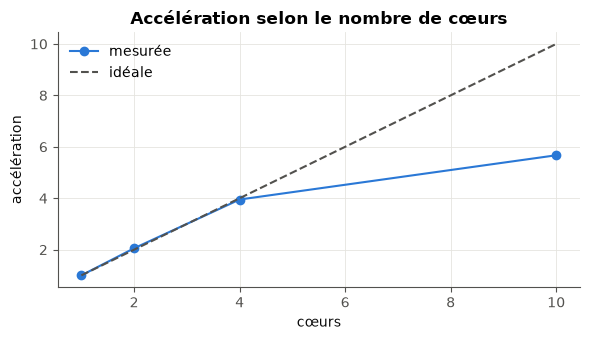

In [22]:
for p in list(PREDS.values()) + [x10_t]:
    p.unpersist()
CŒURS = []
for k in [1, 2, 4, 10]:
    spark.stop()
    spark = creer_spark(f"local[{k}]")
    d = spark.read.option("header", True).schema(SCHEMA).csv(str(UNIVERS[N_COPIES]))
    _, t = chrono(lambda: d.groupBy("Class").agg(F.avg((F.col("satisfaction") == "satisfied").cast("int"))).collect())
    CŒURS.append({"cœurs": k, "temps (s)": t})
    print(f"local[{k:2d}] : {t:5.1f} s")
coeurs = pd.DataFrame(CŒURS).set_index("cœurs")
coeurs["accélération"] = coeurs["temps (s)"].iloc[0] / coeurs["temps (s)"]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(coeurs.index, coeurs.accélération, "o-", color=BLEU, label="mesurée")
ax.plot(coeurs.index, coeurs.index, "--", color=GRIS, label="idéale")
ax.set(title="Accélération selon le nombre de cœurs", xlabel="cœurs", ylabel="accélération"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
spark.stop(); spark = creer_spark(); sc = spark.sparkContext

**Lecture** : de 9,8 s sur 1 cœur à 1,7 s sur 10 cœurs, soit une **accélération d'environ 6** (l'idéal serait 10). C'est bien mieux qu'au TP2 (×1,3 à ×1,6 pour les DataFrames) : la lecture d'un CSV est un travail **purement parallèle** (chaque cœur découpe ses propres fichiers, sans échange), et les 40 fichiers se répartissent bien sur 10 cœurs. Ce qui reste de non parallèle (planification, agrégation finale) explique l'écart à l'idéal.

## [Conclusion]

Section 9 — Corrections apportées au notebook d'origine et conclusion.

---
# 9. Bilan

## 9.1 Les corrections apportées au notebook d'origine

| # | Problème dans le notebook | Conséquence | Ce que fait ce TP |
|---|---|---|---|
| 1 | Chemins Kaggle en dur (`/kaggle/input/...`) | Ne tourne pas en dehors de Kaggle | Chemins locaux |
| 2 | `dropna()` sur le **test** | Le modèle refuse 83 passagers ; impossible en production | `Imputer` dans le pipeline, appris sur l'apprentissage |
| 3 | Note 0 traitée comme la plus mauvaise note | Elle signifie « non applicable » (et est associée à des passagers satisfaits pour le wifi) | Variable `nb_non_notes` |
| 4 | Retards supprimés, seul « en retard oui/non » est gardé | Perte de l'information de durée | Indicateur + log du retard total |
| 5 | Arbre de décision sans limite de profondeur | 100 % en apprentissage : apprentissage par cœur | Profondeur limitée (section 6.2) |
| 6 | Comparaison sur la seule accuracy | Masque le compromis précision / rappel | AUC, précision, rappel, F1 |
| 7 | `GridSearchCV`, `RandomForest`, `SVC` importés mais jamais utilisés ; modèles entraînés deux fois | Code trompeur et plus lent | Chaque modèle entraîné une fois |
| — | *Spécifique au Big Data* : découpage au hasard d'un jeu à quasi-doublons | Score surestimé | Découpage par passager d'origine (section 6.4) |

## 9.2 Conclusion

**Ce que le passage au Big Data change**
- **Le stockage** : le CSV brut (900 Mo) devient un data lake en Parquet, environ 6 fois plus compact et beaucoup plus rapide à interroger. Il est organisé en zones : **brut** (CSV) → **bronze** (Parquet) → **silver** (nettoyé, partitionné par mois) → **gold** (prêt pour le ML).
- **La façon de travailler** : tout se calcule dans Spark, et pandas ne reçoit que des résultats agrégés. Les transformations sont des étapes d'un `Pipeline`, ajusté sur l'apprentissage et réutilisable tel quel en production.
- **Les performances** : à 6,5 millions de lignes, Spark est 4 à 12 fois plus rapide que pandas selon le format, et la lecture accélère fortement avec le nombre de cœurs (×6 avec 10 cœurs).
- **Les contraintes** : la mémoire devient la limite principale (dépassements avec 13 millions de lignes sur un Mac de 16 Go). Certains modèles disparaissent (k plus proches voisins), d'autres sont plus lents (forêts, boosting).

**Ce que le Big Data ne change pas**
- **Les résultats** : les mêmes variables expliquent la satisfaction (embarquement en ligne, wifi, motif du voyage, classe), et le meilleur modèle Spark (forêt aléatoire, 94,6 % sur le test d'origine) ne bat pas XGBoost entraîné sur les 104 000 lignes d'origine (96,3 %).
- **Le volume ne remplace pas l'information** : la courbe d'apprentissage montre qu'on atteint presque le même score avec 1 % des données.

**Les pièges spécifiques mis en évidence**
- Les **quasi-doublons** faussent l'évaluation si l'on découpe au hasard : il faut découper par passager.
- À grande échelle, même des taux de défauts infimes (0,05 % de doublons) concernent des milliers de lignes : le contrôle qualité doit être **systématique et automatisé**.

**Suite** : le déploiement. Le `PipelineModel` sauvegardé (`artefacts/modele_satisfaction_spark`) sera servi par une API dans un conteneur Docker.

In [23]:
spark.stop()
print("Session Spark arrêtée")

Session Spark arrêtée
